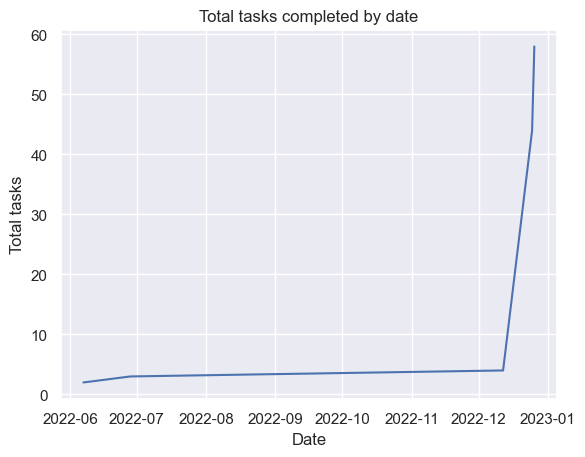

In [42]:
import os
import re
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
results = pd.DataFrame(columns=['date', 'count'])

# Recursively walk through the directory and search for strings
def search_directory(directory):
    date_counts = {}
    # Find all markdown files in the directory and its subdirectories
    files = [os.path.join(root, file) for root, dirs, files in os.walk(directory) for file in files if file.endswith('.md')]

    # Initialize counter for total number of strings found
    total_count = 0

    # Iterate over all markdown files
    for file in files:
        with open(file, 'r') as f:
            contents = f.read()
            matches = re.findall(r"✅\s(\d{4}-\d{2}-\d{2})", contents)
            for match in matches:
                date = datetime.strptime(match, '%Y-%m-%d')
                if date not in date_counts:
                    # Initialize count for this date
                    date_counts[date] = 1
                else:
                    # Increment count for this date
                    date_counts[date] += 1
    return date_counts


directory = "/home/zack/SparkleShare/github.com/Notes/Obsidian"
# Run the search on the desired directory
counts = search_directory(directory)

df = pd.DataFrame(list(counts.items()), columns=['date', 'count']).sort_values(by='date')
df['cumulative_total'] = df['count'].cumsum()

sns.set_theme(style="darkgrid")
# Create the plot
sns.lineplot(x='date', y='cumulative_total', data=df)

# Set the x-axis label
plt.xlabel('Date')

# Set the y-axis label
plt.ylabel('Total tasks')

# Set the title
plt.title('Total tasks completed by date')

# Show the plot
plt.show()

In [29]:
df["Increment"] = df["count"].diff(periods=2).fillna(0)
df

,date,count,cumulative_total,Increment
2,2022-06-07,2,2,0.0
3,2022-06-28,1,3,0.0
4,2022-12-12,1,4,-1.0
1,2022-12-25,40,44,39.0
0,2022-12-26,14,58,13.0


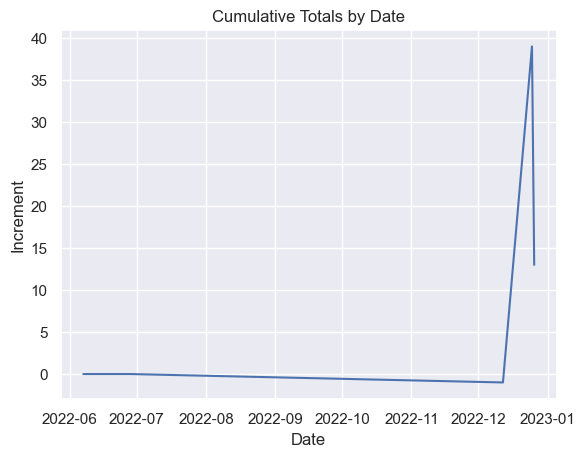

In [41]:
df["Increment"] = df["count"].diff(periods=2).fillna(0)

# Create the plot
sns.lineplot(x='date', y='Increment', data=df)

# Set the x-axis label
plt.xlabel('Date')

# Set the y-axis label
plt.ylabel('Number of tasks')

# Set the title
plt.title('Tasks completed by date')

# Show the plot
plt.show()

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter

# Define the dataframe
df = pd.DataFrame({
    'date': [datetime(2022, 1, 1), datetime(2022, 1, 2), datetime(2022, 1, 3)],
    'cumulative_total': [5, 8, 15],
})

# Set the date column as the index
df.set_index('date', inplace=True)

# Convert the index to a numeric array
x = df.index.to_series().apply(datetime.timestamp)

# Convert the epoch seconds to a Timestamp object
x = pd.to_datetime(x, unit='s')

# Create the plot with lowess smoothing
sns.regplot(x=x, y='cumulative_total', data=df, lowess=True)

# Set the x-axis label
plt.xlabel('Date')

# Set the y-axis label
plt.ylabel('Cumulative Total')

# Set the title
plt.title('Cumulative Totals by Date')

# Create a DateFormatter object to format the x-axis tick labels
formatter = DateFormatter('%Y-%m-%d')

# Set the x-axis tick labels to the formatted dates
plt.gca().xaxis.set_major_formatter(formatter)

# Show the plot
plt.show()

In [ ]:
x

In [24]:
import re

# Define the regex pattern
pattern = r"\u2705 \d{4}-\d{2}-\d{2}"

# Compile the regex pattern
regex = re.compile(pattern)

# Find all matches in the input string
matches = regex.findall("✅ 2022-12-26 ✅ 2022-12-27")

# Print the matches
print(matches)


['✅ 2022-12-26', '✅ 2022-12-27']
